# Gut Microbiome: Reproducing Data

This will inspect the processed geno/phenotype data and use it to calculate the narrow-sense heritability $h^2$.

There are 320 mice (`N`) and 32,625 SNPs (`M`).

The genotype data is in `reference_code/Data/genotypes/`:
- `clean_f2.bed` - genotype values
- `clean_f2.bim` - SNP name, position, alleles
- `clean_f2.fam` - mouse IDs

==> Will decode these to produce an `M x N` genotype array.

The phenotype data is in `reference_code/Data/phenotypes/`:
- `genus_table_f2_core.csv` - this shows the relative abundance of each bacteria for each individual.

==> Each of these is a phenotype measurement to calculate $h^2$ for.

This will tell us if genetically similar mice also have similar abundance of this bacterium.

In [122]:
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "reference_code").exists():
    ROOT = ROOT.parent
DATA_PATH = str(ROOT / "reference_code/Data")
ASSAY = "DNA"  # Fit DNA and RNA separately.
# ASV = observed 16S sequence variant
LEVEL = "otu"

# "table" is the R script's taxon list
TAXA_SELECTION = "table"


## Get Genotype/Phenotype Data

In [123]:
# Getting the genotype data:
GENOTYPE_PATH = DATA_PATH + "/genotypes/clean_f2"

mouse_ids = pd.read_csv(F"{GENOTYPE_PATH}.fam",
                        sep=r'\s+', header=None,
                        names=["FID", "IID", "father", "mother", "sex", "phenotype"], dtype="str")
# converted to indices so they can be used as labels in pandas
# we rename them b/c in the phenotypes they use a dot
mouse_indices = pd.Index(mouse_ids.IID.str.replace("/", ".", regex=False), name="mouse_id")

# A1/A2 are allele labels; reference/alternate status is not established.
snp_info = pd.read_csv(F"{GENOTYPE_PATH}.bim",
                       sep=r'\s+', header=None,
                       names=["chr", "snp", "cM", "position", "A1", "A2"])

def decode_bed(path, n_samples, n_snps):
    # https://www.cog-genomics.org/plink/1.9/formats#bed
    raw = np.fromfile(path, dtype=np.uint8)
    # double-check the magic number for plink
    assert raw[:3].tolist() == [0x6c, 0x1b, 0x01], "magic number isn't right"

    stride = (n_samples + 3) // 4
    assert raw.size == 3 + stride*n_snps, "bed dims don't match the fam/bin"
    packed = raw[3:].reshape(n_snps, stride)
    bits = ((packed[:, :, None] >> np.array([0,2,4,6], dtype=np.uint8)) & 3)
    bits = bits.reshape(n_snps, stride*4)[:, :n_samples]
    return np.array([2., np.nan, 1., 0.])[bits]

N = len(mouse_ids)
M = len(snp_info)
G = decode_bed(F"{GENOTYPE_PATH}.bed", N, M)

# convert it all into an easy-to-access pandas db
dataset = pd.DataFrame(G, index=snp_info.snp, columns=mouse_indices)

print("Processed data:")
display(dataset.head(n=20))

print("Genotype array (first 10 x 10):")
display(G[:10, :10])

print(F"Genotype shape: {G.shape}")

Processed data:


mouse_id,HZA.HZF.03.B.1M,HZA.HZF.03.B.2M,HZA.HZF.03.B.3M,HZA.HZF.04.B.1M,HZA.HZF.05.B.3M,HZA.HZF.05.B.4M,HZA.HZF.06.C.3M,HZA.HZF.06.C.4M,HZA.HZF.06.C.5M,HZB.HZG.01.C.1M,...,HZH.HZC.07.A.2M,HZH.HZC.07.A.3M,HZH.HZC.09.A.1M,HZH.HZC.09.A.2M,HZH.HZC.09.A.3M,HZH.HZC.09.A.4M,HZH.HZC.09.A.5M,HZH.HZC.10.A.1M,HZH.HZC.10.A.2M,HZH.HZC.10.A.3M
snp,,,,,,,,,,,,,,,,,,,,,
UNCHS000002,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
JAX00240610,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
UNCHS000005,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,...,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
UNCHS000006,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
JAX00000040,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
UNCHS000007,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
UNCHS000009,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
JAX00000058,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,...,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
JAX00000089,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,...,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0


Genotype array (first 10 x 10):


array([[1., 1., 1., 1., 1., 1., 1., 0., 0., 0.],
       [0., 1., 0., 1., 0., 0., 1., 0., 1., 0.],
       [1., 1., 1., 1., 1., 1., 1., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 1., 1., 1., 1., 1., 1., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 1., 0., 1., 1., 0., 1., 0., 0.],
       [1., 1., 1., 1., 1., 1., 1., 0., 0., 0.],
       [1., 1., 1., 1., 1., 1., 1., 0., 0., 0.],
       [1., 1., 1., 1., 1., 1., 1., 0., 0., 0.]])

Genotype shape: (32625, 320)


In [124]:
PHENOTYPE_PATH = DATA_PATH + "/phenotypes"

def map_pheno(assay="DNA", level="genus", selection="table"):
    pheno = pd.read_csv(f"{PHENOTYPE_PATH}/{level}_table_f2_core.csv", index_col=0)
    core = pd.read_csv(f"{DATA_PATH}/trait.list.{assay.lower()}.csv", sep=";")
    core_taxa = core[level].dropna().unique()
    if selection == "table":
        taxa = pheno.columns
    elif selection == "core_list":
        taxa = core_taxa
    else:
        raise ValueError("selection must be table or core_list")

    pheno = pheno.loc[pheno.index.str.endswith(f"_{assay}"), taxa].copy()
    pheno.index = pheno.index.str.removesuffix(f"_{assay}")
    assert pheno.index.is_unique and dataset.columns.is_unique

    # Drop unavailable assay profiles, rather than treating missing abundance as zero.
    keep = dataset.columns.isin(pheno.index)
    phen = pheno.loc[dataset.columns[keep]].copy()
    if not np.isfinite(phen.to_numpy()).all():
        raise ValueError("within-profile missing values: fit traits on their observed mouse subsets")
    
    geno = G[:, keep]
    assert phen.index.equals(dataset.columns[keep])

    print(f"{assay}:\n\t# Mice: {len(phen)}\n\t# taxa: {phen.shape[1]}\n\tMice w/o assay: {(~keep).sum()}")
    return phen, geno

pheno_dataset, G_filtered = map_pheno(ASSAY, LEVEL, TAXA_SELECTION)
display(pheno_dataset.head())


DNA:
	# Mice: 286
	# taxa: 98
	Mice w/o assay: 34


,SV1,SV2,SV3,SV4,SV5,SV6,SV7,SV9,SV10,SV12,...,SV243,SV246,SV248,SV264,SV281,SV293,SV370,SV376,SV396,SV746
HZA.HZF.03.B.1M,0.3633,0.0,0.0,0.0267,0.0,0.0470,0.0490,0.0,0.0322,0.0,...,0.0026,0.000,0.0071,0.0,0.0,0.0,0.0052,0.0,0.0,0.0000
HZA.HZF.03.B.2M,0.5684,0.0,0.0,0.0165,0.0,0.0252,0.0000,0.0,0.0162,0.0,...,0.0046,0.000,0.0000,0.0,0.0,0.0,0.0012,0.0,0.0,0.0009
HZA.HZF.03.B.3M,0.2634,0.0,0.0,0.0151,0.0,0.0046,0.0000,0.0,0.0169,0.0,...,0.0015,0.000,0.0000,0.0,0.0,0.0,0.0037,0.0,0.0,0.0040
HZA.HZF.04.B.1M,0.4093,0.0,0.0,0.0294,0.0,0.0356,0.0691,0.0,0.0234,0.0,...,0.0001,0.000,0.0000,0.0,0.0,0.0,0.0006,0.0,0.0,0.0000
HZA.HZF.05.B.4M,0.3685,0.0,0.0,0.0741,0.0,0.0637,0.0432,0.0,0.0498,0.0,...,0.0003,0.002,0.0000,0.0,0.0,0.0,0.0012,0.0,0.0,0.0000


## REML estimate with subcrosses

Variance is estimated with the MLM we used in calss with an additional subcross parameter:

$$V=\sigma_g^2K+\sigma_s^2F+\sigma_e^2I.$$

`K` measures genetic relatedness; `F[i,j]` is 1 when two mice share a subcross.
The fixed effect is an intercept. Subcross is a random effect, as in the paper.
We can infer its labels from the eight mouse-ID prefixes in 
[Figure 1 supplement 6](https://elifesciences.org/articles/75419/figures#fig1s6).

The paper also includes mating pair, which is not available anywhere in their supplementary material or GitHub (the code refers to `Phenotypes_histology_new.csv`, which doesn't appear to be publicly accessible). I have contacted the author to see if it would be possible to access these, since it seems like an oversight rather than that data being closed-access.


In [125]:
# Construct the centered GRM (rows of G_filtered are SNPs).
# (1) Remove SNPs with no observed genotype calls.
each_snp_count = np.isfinite(G_filtered).sum(axis=1)
G_observed = G_filtered[each_snp_count > 0]

# (2) Subtract the mean dosage of each SNP.
snp_mean = np.nanmean(G_observed, axis=1)
Z = G_observed - snp_mean[:, None]

# (3) Missing centered calls become 0
Z = np.where(np.isnan(Z), 0.0, Z)

# (4) Remove SNPs with no variation among these mice.
Z = Z[np.sum(Z**2, axis=1) > 0]
M, N = Z.shape
assert M > 0
K = (Z.T @ Z) / M
assert K.shape == (len(pheno_dataset), len(pheno_dataset))
assert np.isfinite(K).all()

# Get subcrosses from original IDs containing the /
# Ex: HZA/HZF.03.B.1M -> HZA/HZF.
all_subcrosses = pd.Series(
    mouse_ids.IID.str.split(".").str[0].to_numpy(),
    index=mouse_indices,
    name="subcross",
)
expected = {"HZA/HZF", "HZB/HZG", "HZC/HZA", "HZD/HZE",
            "HZE/HZB", "HZF/HZH", "HZG/HZD", "HZH/HZC"}
assert set(all_subcrosses) == expected
assert all_subcrosses.value_counts().eq(40).all()

# Align the grouping labels with the phenotype rows and genotype columns.
subcrosses = all_subcrosses.loc[pheno_dataset.index]
labels = subcrosses.to_numpy()
F = (labels[:, None] == labels[None, :]).astype(float)
I = np.eye(N)
print(f"{N} mice, {M} SNPs; mean GRM diagonal: {np.diag(K).mean():.4f}")
display(subcrosses.value_counts().sort_index())

286 mice, 32625 SNPs; mean GRM diagonal: 0.3243


subcross
HZA/HZF    35
HZB/HZG    36
HZC/HZA    36
HZD/HZE    36
HZE/HZB    36
HZF/HZH    35
HZG/HZD    36
HZH/HZC    36
Name: count, dtype: int64

### REML Estimate of $h^2$

Up to a parameter-independent constant, the negative restricted log likelihood is

$$\frac12\left[\log|C|+\log|X^TC^{-1}X|+(N-1)\left(1+\log(2\pi\hat t)\right)\right].$$

After scaling the phenotypes we convert them back to the original analysis scale.

Also, in the paper, they use `inv_logit` (the R script's transformation
$1/(1+e^{-a})$ of relative abundance $a$), so that's replicated here.


In [126]:
from scipy.linalg import cho_factor, cho_solve
from scipy.optimize import minimize

# Keep a small positive residual weight so C stays invertible.
RESIDUAL_FLOOR = 1e-6

def reml_likelihood(weights, Y, K, F, X=None):
    """Negative profiled REML log likelihood for V = g*K + s*F + r*I.

    Fixed effects are the columns of X (default: an intercept). Returns
    (negative_loglik, total_scale, beta). The intercept-only case reproduces
    the original h^2 likelihood exactly, so calc_reml is unchanged numerically.
    """
    N = len(Y)
    if X is None:
        X = np.ones((N, 1))
    p = X.shape[1]
    I = np.eye(N)
    genetic, subcross = weights
    residual = 1.0 - genetic - subcross
    if genetic < 0 or subcross < 0 or residual <= 0:
        return np.inf, np.nan, None

    C = genetic * K + subcross * F + residual * I
    try:
        # Cholesky solves C @ solution = rhs without forming C^-1.
        factor = cho_factor(C, lower=True, check_finite=False)
        Cinv_X = cho_solve(factor, X, check_finite=False)
        Cinv_Y = cho_solve(factor, Y, check_finite=False)

        # Generalized least squares for the fixed effects.
        Xt_Cinv_X = X.T @ Cinv_X
        sign, logdet_X = np.linalg.slogdet(np.atleast_2d(Xt_Cinv_X))
        if sign <= 0:
            return np.inf, np.nan, None
        beta = np.linalg.solve(Xt_Cinv_X, X.T @ Cinv_Y)
        residuals = Y - X @ beta
        Cinv_residuals = Cinv_Y - Cinv_X @ beta
        scale = (residuals @ Cinv_residuals) / (N - p)
        if scale <= 0:
            return np.inf, np.nan, None

        # det(C) = squared product of Cholesky diagonals.
        logdet_C = 2 * np.log(np.diag(factor[0])).sum()
        negative_loglik = 0.5 * (
            logdet_C + logdet_X + (N - p) * (1 + np.log(2 * np.pi * scale))
        )
        return negative_loglik, scale, beta
    except np.linalg.LinAlgError:
        return np.inf, np.nan, None


def fit_reml(Y, K, F, X=None, starts=([0.1, 0.1], [0.7, 0.1], [0.1, 0.7])):
    """Multi-start SLSQP fit of the variance-component weights.

    Returns (weights[g, s, r], scale, beta, fits) where fits is the list of
    successful optimizer results (used for convergence diagnostics).
    """
    fits = []
    for start in starts:
        fit = minimize(
            lambda w: reml_likelihood(w, Y, K, F, X)[0],
            x0=list(start),
            method="SLSQP",
            bounds=[(0, 1), (0, 1)],
            constraints={"type": "ineq", "fun": lambda w: 1 - RESIDUAL_FLOOR - w.sum()},
            options={"maxiter": 300, "ftol": 1e-9},
        )
        if (fit.success and np.isfinite(fit.fun) and (fit.x >= 0).all()
                and fit.x.sum() <= 1 - RESIDUAL_FLOOR + 1e-9):
            fits.append(fit)
    if not fits:
        return None, None, None, fits
    best = min(fits, key=lambda fit: fit.fun)
    nll, scale, beta = reml_likelihood(best.x, Y, K, F, X)
    weights = np.array([best.x[0], best.x[1], 1 - best.x.sum()])
    return weights, scale, beta, fits


In [127]:
# Fit each bacterial trait. The matrices are reused across the taxa.
traits = 1 / (1 + np.exp(-pheno_dataset))


def calc_reml(K, name="h2"):
    K = np.asarray(K, dtype=float)
    N = len(traits)
    assert K.shape == F.shape == (N, N)
    assert np.isfinite(K).all() and np.allclose(K, K.T)
    records = []
    for bacteria in traits.columns:
        phenotype = traits[bacteria].to_numpy(dtype=float)
        if not np.isfinite(phenotype).all():
            raise ValueError(f"Missing phenotype values for {bacteria}")
        if np.ptp(phenotype) == 0:
            records.append({"taxon": bacteria, "status": "constant_trait", "n_mice": N})
            continue
        sd = phenotype.std(ddof=0)
        Y = (phenotype - phenotype.mean()) / sd

        # Intercept-only fixed effect: same model as before.
        weights, scale, beta, fits = fit_reml(Y, K, F)
        if weights is None:
            records.append({"taxon": bacteria, "status": "optimizer_failed", "n_mice": N})
            continue

        # Undo phenotype scaling to report coefficients in analysis-trait units.
        variances = weights * scale * sd**2
        h2_coefficient = weights[0]

        # K does not have mean diagonal 1. This second fraction measures the
        # genetic share of average modeled marginal variance, including K's scale.
        contributions = variances * np.array([np.diag(K).mean(), 1.0, 1.0])
        h2_marginal = contributions[0] / contributions.sum()

        best_nll = min(fit.fun for fit in fits)
        records.append({
            "taxon": bacteria,
            # genetic, subcross, environment
            "sigma2_g": variances[0], "sigma2_s": variances[1],
            "sigma2_e": variances[2],
            "h2_coefficient": h2_coefficient,
            "h2_marginal": h2_marginal,
            "negative_REML_standardized": best_nll,
            "status": "converged",
        })

    results = pd.DataFrame(records).set_index("taxon")

    output = "../analysis/heritability_outputs"
    results.to_csv(output + f"/REML_subcross_{ASSAY}_{LEVEL}_{TAXA_SELECTION}({name}).csv")
    return results


raw_h2 = calc_reml(K)
summary_results = raw_h2[["h2_coefficient"]].copy()
raw_h2.head(n=10)


,sigma2_g,sigma2_s,sigma2_e,h2_coefficient,h2_marginal,negative_REML_standardized,status
taxon,,,,,,,
SV1,0.000000e+00,2.906453e-04,0.002040,0.000000e+00,0.000000e+00,397.269375,converged
SV2,9.014996e-04,6.118181e-04,0.001528,2.964487e-01,1.202354e-01,374.968018,converged
SV3,0.000000e+00,2.090682e-04,0.000444,0.000000e+00,0.000000e+00,368.504023,converged
SV4,2.236936e-05,6.467583e-06,0.000060,2.508729e-01,9.797775e-02,397.933163,converged
SV5,4.962914e-19,2.237398e-06,0.000086,5.639704e-15,1.829230e-15,406.798442,converged
SV6,1.913890e-05,7.322132e-06,0.000046,2.644623e-01,1.044397e-01,391.554821,converged
SV7,5.117320e-05,8.744575e-06,0.000037,5.295462e-01,2.674471e-01,371.280600,converged
SV9,1.677277e-07,6.034003e-21,0.000157,1.069369e-03,3.470991e-04,407.724513,converged
SV10,1.214152e-05,3.014721e-06,0.000015,3.979365e-01,1.765343e-01,387.079475,converged


## Chip Heritability Estimate

The researchers use a standardized SNP relationship matrix ($K_{std}$) instead of a centered GRM like in the narrow-sense estimates. Then REML optimization can be used again with:

$$ V = \sigma^2_gK_{std} + \sigma^2_sF + \sigma^2_eI $$

In [128]:
# Do standardization (like time above but / sqrt(variance))
geno = G_filtered[np.isfinite(G_filtered).sum(axis=1) > 1].copy()
mean = np.nanmean(geno, axis=1)
variance = np.nanvar(geno, axis=1, ddof=1)

# Remove SNPs w/ no variation:
keep = np.isfinite(variance) & (variance > 0)
geno = geno[keep]
mean = mean[keep]
variance = variance[keep]

# Standardize SNPs
W = (geno - mean[:, None]) / np.sqrt(variance[:,None])
# Missing values become 0
W = np.where(np.isnan(W), 0.0, W)

K_std = (W.T @ W) / W.shape[0]

reml_chip = calc_reml(K_std, "chip_heredity")

# Resulting chip coefficient ratio is og^2 / (og^2 + os^2 + oe^2)
summary_results["chip_h"] = reml_chip["sigma2_g"] / (reml_chip["sigma2_g"] + reml_chip["sigma2_s"] + reml_chip["sigma2_e"])

summary_results.head(n=10)


,h2_coefficient,chip_h
taxon,,
SV1,0.000000e+00,5.288818e-16
SV2,2.964487e-01,1.219288e-01
SV3,0.000000e+00,9.744230e-17
SV4,2.508729e-01,1.292551e-01
SV5,5.639704e-15,0.000000e+00
SV6,2.644623e-01,9.679036e-02
SV7,5.295462e-01,3.043941e-01
SV9,1.069369e-03,2.562576e-04
SV10,3.979365e-01,1.738932e-01


In [129]:
# Example of a taxon result:
summary_results.loc["SV97"]

h2_coefficient    0.504903
chip_h            0.274390
Name: SV97, dtype: float64

## PVE Estimation

To calculate the PVE, the researchers add a particular SNP's additive and dominant effects as fixed predictors, refit the model, and measure how much variance the predictors explain. We pull the already calculated GWAS statistics from the supplementary materials; it can be downloaded from [here](https://cdn.elifesciences.org/articles/75419/elife-75419-supp3-v1.xlsx) and then put it in the `data` folder.

In [130]:
GWAS_PATH = "../data/elife-75419-supp3-v1.xlsx"

gwas = pd.read_excel(GWAS_PATH)
gwas.head()

,trait,P.type,sig.type,chr,chr.num,chr_bin,length,start.LD.pos,stop.LD.pos,sig.snps,...,markers,closest_gene,closest_gene_type,closest_gene_description,total_genes,list_total_genes,total_protein_coding_genes,list_protein_coding_genes,tax_level,dna.rna
0,C_Bacilli,P,bon,18,18,18_1,0.959184,42179093,43138277,2,...,"UNC29131523, UNC29132165",4933407I08Rik,antisense,RIKEN cDNA 4933407I08 gene [Source:MGI Symbol;...,21,"Plac8l1, Gm18086, Gm5504, Lars, Rps19-ps4, Gm4...",7,"Plac8l1, Lars, Rbm27, Pou4f3, Tcerg1, Gpr151, ...",class,DNA
1,C_Bacilli,add.P,bon,18,18,18_1,0.959184,42179093,43138277,2,...,"UNC29131523, UNC29132165",4933407I08Rik,antisense,RIKEN cDNA 4933407I08 gene [Source:MGI Symbol;...,21,"Plac8l1, Gm18086, Gm5504, Lars, Rps19-ps4, Gm4...",7,"Plac8l1, Lars, Rbm27, Pou4f3, Tcerg1, Gpr151, ...",class,DNA
2,C_Bacilli,dom.P,bon,18,18,18_1,0.959184,42179093,43138277,2,...,"UNC29131523, UNC29132165",4933407I08Rik,antisense,RIKEN cDNA 4933407I08 gene [Source:MGI Symbol;...,21,"Plac8l1, Gm18086, Gm5504, Lars, Rps19-ps4, Gm4...",7,"Plac8l1, Lars, Rbm27, Pou4f3, Tcerg1, Gpr151, ...",class,DNA
3,C_Deferribacteres,dom.P,bon,5,5,5_1,3.779751,121747120,125526871,2,...,"UNC10048917, UNCHS015800",Mir7031,miRNA,microRNA 7031 [Source:MGI Symbol;Acc:MGI:5531241],154,"Atxn2, Sh2b3, Mir7031, 1700008B11Rik, 4933437G...",79,"Atxn2, Sh2b3, Pheta1, Cux2, Myl2, Ccdc63, Ppp1...",class,DNA
4,F_Deferribacteraceae,dom.P,bon,5,5,5_1,3.779751,121747120,125526871,2,...,"UNC10048917, UNCHS015800",Mir7031,miRNA,microRNA 7031 [Source:MGI Symbol;Acc:MGI:5531241],154,"Atxn2, Sh2b3, Mir7031, 1700008B11Rik, 4933437G...",79,"Atxn2, Sh2b3, Pheta1, Cux2, Myl2, Ccdc63, Ppp1...",family,DNA


### PVE of Signifiant SNPs

Following `PVE/PVE_all_snps.R`, select `P.type == "P"` and combine the unique `markers` for each taxon. Fit these markers **jointly**, first additive-only, then additive + dominance, using the same complete-case mice for both fits.

The combined model uses the full centered GRM, as in that R script.

Our covariance is genetic + subcross + residual. The original PVE script uses mating pair instead of subcross, so this remains an approximation to their analysis.
These are in-sample PVEs for published significant markers, not independent GWAS or out-of-sample validation. Missing hits or failed fits stay NaN, not zero.

The marginal PVE is
$\mathrm{Var}(X\hat\beta)/[\mathrm{Var}(X\hat\beta)+\mathrm{mean}(\mathrm{diag}(V))]$.
Values are stored as fractions; multiply by 100 for percentages.


In [131]:
# Pick the same marker sets as the authors' combined-PVE script.
pve_hits = gwas.loc[
    gwas["dna.rna"].eq(ASSAY) & gwas["tax_level"].eq(LEVEL)
    # Select the additive + dom effect SNPs
    & gwas["P.type"].isin(["P", "add.P", "dom.P"])
].copy()

markers_by_taxon = {}
for bacteria, rows in pve_hits.groupby("trait"):
    # Several significant regions can contain the same SNP. Count it once.
    markers = [snp.strip() for entry in rows["markers"].dropna()
               for snp in str(entry).split(",") if snp.strip()]
    markers_by_taxon[bacteria] = list(dict.fromkeys(markers))

# Use the original genotype DataFrame so marker labels cannot get out of step
# with a genotype array after SNP filtering. Columns follow phenotype mouse order.
assert dataset.index.is_unique
pve_genotypes = dataset.loc[:, pheno_dataset.index]
print(f"{len(markers_by_taxon)} taxa with selected SNPs for {ASSAY}, {LEVEL}")


38 taxa with selected SNPs for DNA, otu


In [132]:
def fit_snp_pve(Y, X, K_part, F_part):
    """Joint REML fit of fixed SNP effects + genetic/subcross random effects.

    PVE is the marginal R^2 (Nakagawa & Schielzeth) used by r.squaredGLMM in
    the authors' PVE_all_snps.R:

        PVE = var(SNP fitted) / (var(SNP fitted) + sigma2_g + sigma2_s + sigma2_e)

    The SNP fitted values exclude the intercept, and every variance component
    is placed on the single REML total scale so the ratio is self-consistent.
    This calls the same reml_likelihood / fit_reml as the h^2 estimate; only
    the fixed-effect design X differs (intercept + SNP columns).
    """
    n = len(Y)
    if n < 4:
        return {"pve": np.nan, "status": "too_few_mice"}
    if np.ptp(Y) == 0:
        return {"pve": np.nan, "status": "constant_trait"}

    # Column-space basis of the centered SNP predictors (no intercept here).
    # Linked SNPs can give redundant columns; an orthonormal basis preserves
    # the fitted values without estimating non-identifiable SNP coefficients.
    centered_X = X - X.mean(axis=0)
    U, singular, _ = np.linalg.svd(centered_X, full_matrices=False)
    tolerance = max(centered_X.shape) * np.finfo(float).eps * singular[0]
    rank = int((singular > tolerance).sum())
    if rank == 0:
        return {"pve": np.nan, "status": "no_SNP_variation"}
    X_snp = U[:, :rank]                               # centered, full column rank
    X_fit = np.column_stack([np.ones(n), X_snp])      # intercept used in the fit
    p = X_fit.shape[1]
    if n <= p:
        return {"pve": np.nan, "status": "no_residual_df"}

    # PVE is invariant to rescaling Y as long as fixed and random variances
    # share the scale, which they do below (both come from the same fit).
    Y = (Y - Y.mean()) / Y.std(ddof=0)

    weights, scale, beta, fits = fit_reml(Y, K_part, F_part, X_fit)
    if weights is None:
        return {"pve": np.nan, "status": "optimizer_failed"}

    # One scale for numerator and denominator.
    var_snp = np.var(X_snp @ beta[1:], ddof=1)        # exclude the intercept
    sigma2_g, sigma2_s, sigma2_e = scale * weights
    pve = var_snp / (var_snp + sigma2_g + sigma2_s + sigma2_e)

    best = min(fits, key=lambda fit: fit.fun)
    spread = max(fit.fun for fit in fits) - best.fun
    status = "converged"
    if weights[2] <= RESIDUAL_FLOOR * 1.1:
        status = "residual_floor"
    elif spread > 1e-4:
        status = "starts_disagree"
    elif len(fits) < 3:
        status = "some_starts_failed"
    return {"pve": pve, "status": status, "n_mice": n,
            "predictor_columns": X.shape[1], "predictor_rank": rank,
            "variance_fixed": var_snp, "sigma2_g": sigma2_g,
            "sigma2_s": sigma2_s, "sigma2_e": sigma2_e,
            "successful_starts": len(fits), "start_objective_spread": spread}


In [134]:
pve_records = []
for bacteria in pheno_dataset.columns:
    markers = markers_by_taxon.get(bacteria, [])
    record = {"taxon": bacteria, "n_snps": len(markers),
              "markers": ", ".join(markers)}
    if not markers:
        record.update(pve_additive=np.nan, pve_additive_dominance=np.nan,
                      additive_status="no_selected_SNPs",
                      additive_dominance_status="no_selected_SNPs")
        pve_records.append(record)
        continue
    missing = [snp for snp in markers if snp not in pve_genotypes.index]
    if missing:
        raise ValueError(f"Missing genotypes for {bacteria}: {missing}")

    # Complete cases for all selected SNPs: use identical mice in both models.
    genotypes = pve_genotypes.loc[markers].to_numpy(float).T
    phenotype = pheno_dataset[bacteria].to_numpy(float)
    keep = np.isfinite(genotypes).all(axis=1) & np.isfinite(phenotype)
    genotypes = genotypes[keep]
    Y = 1 / (1 + np.exp(-phenotype[keep]))
    K_part = K[np.ix_(keep, keep)]
    F_part = F[np.ix_(keep, keep)]
    additive = 1 - genotypes
    dominance = (genotypes == 1).astype(float)
    record["n_mice"] = int(keep.sum())

    for name, X in [("additive", additive),
                    ("additive_dominance", np.column_stack([additive, dominance]))]:
        fit = fit_snp_pve(Y, X, K_part, F_part)
        # Retain all diagnostics. Only converged fits feed the plot columns.
        record.update({f"{name}_{key}": value for key, value in fit.items()})
        record[f"pve_{name}"] = fit["pve"] if fit["status"] == "converged" else np.nan
    pve_records.append(record)

pve_results = pd.DataFrame(pve_records).set_index("taxon")
summary_results["pve_additive"] = pve_results["pve_additive"]
summary_results["pve_additive_dominance"] = pve_results["pve_additive_dominance"]

output = "./heritability_outputs"
pve_results.to_csv(output + f"/PVE_joint_{ASSAY}_{LEVEL}_{TAXA_SELECTION}.csv")
summary_results.to_csv(output + f"/heritability_and_PVE_{ASSAY}_{LEVEL}_{TAXA_SELECTION}.csv")
print(pve_results[["additive_status", "additive_dominance_status"]].value_counts())
display(summary_results)


additive_status   additive_dominance_status
no_selected_SNPs  no_selected_SNPs             60
converged         converged                    38
Name: count, dtype: int64


,h2_coefficient,chip_h,pve_additive,pve_additive_dominance
taxon,,,,
SV1,0.000000e+00,5.288818e-16,NaN,NaN
SV2,2.964487e-01,1.219288e-01,NaN,NaN
SV3,0.000000e+00,9.744230e-17,0.041734,0.098313
SV4,2.508729e-01,1.292551e-01,NaN,NaN
SV5,5.639704e-15,0.000000e+00,0.197574,0.387126
...,...,...,...,...
SV293,0.000000e+00,0.000000e+00,NaN,NaN
SV370,1.928000e-01,5.666064e-02,NaN,NaN
SV376,6.684307e-14,0.000000e+00,NaN,NaN


## Reproduce the First Figure

The first cell plots the `h2_coefficient` results from earlier. The second makes an estimate of the original figure using just the DNA estimates.

(The plotting code was written with significant help from GPT-6 Astra to make it appear as visually similar as possible to the real plot)

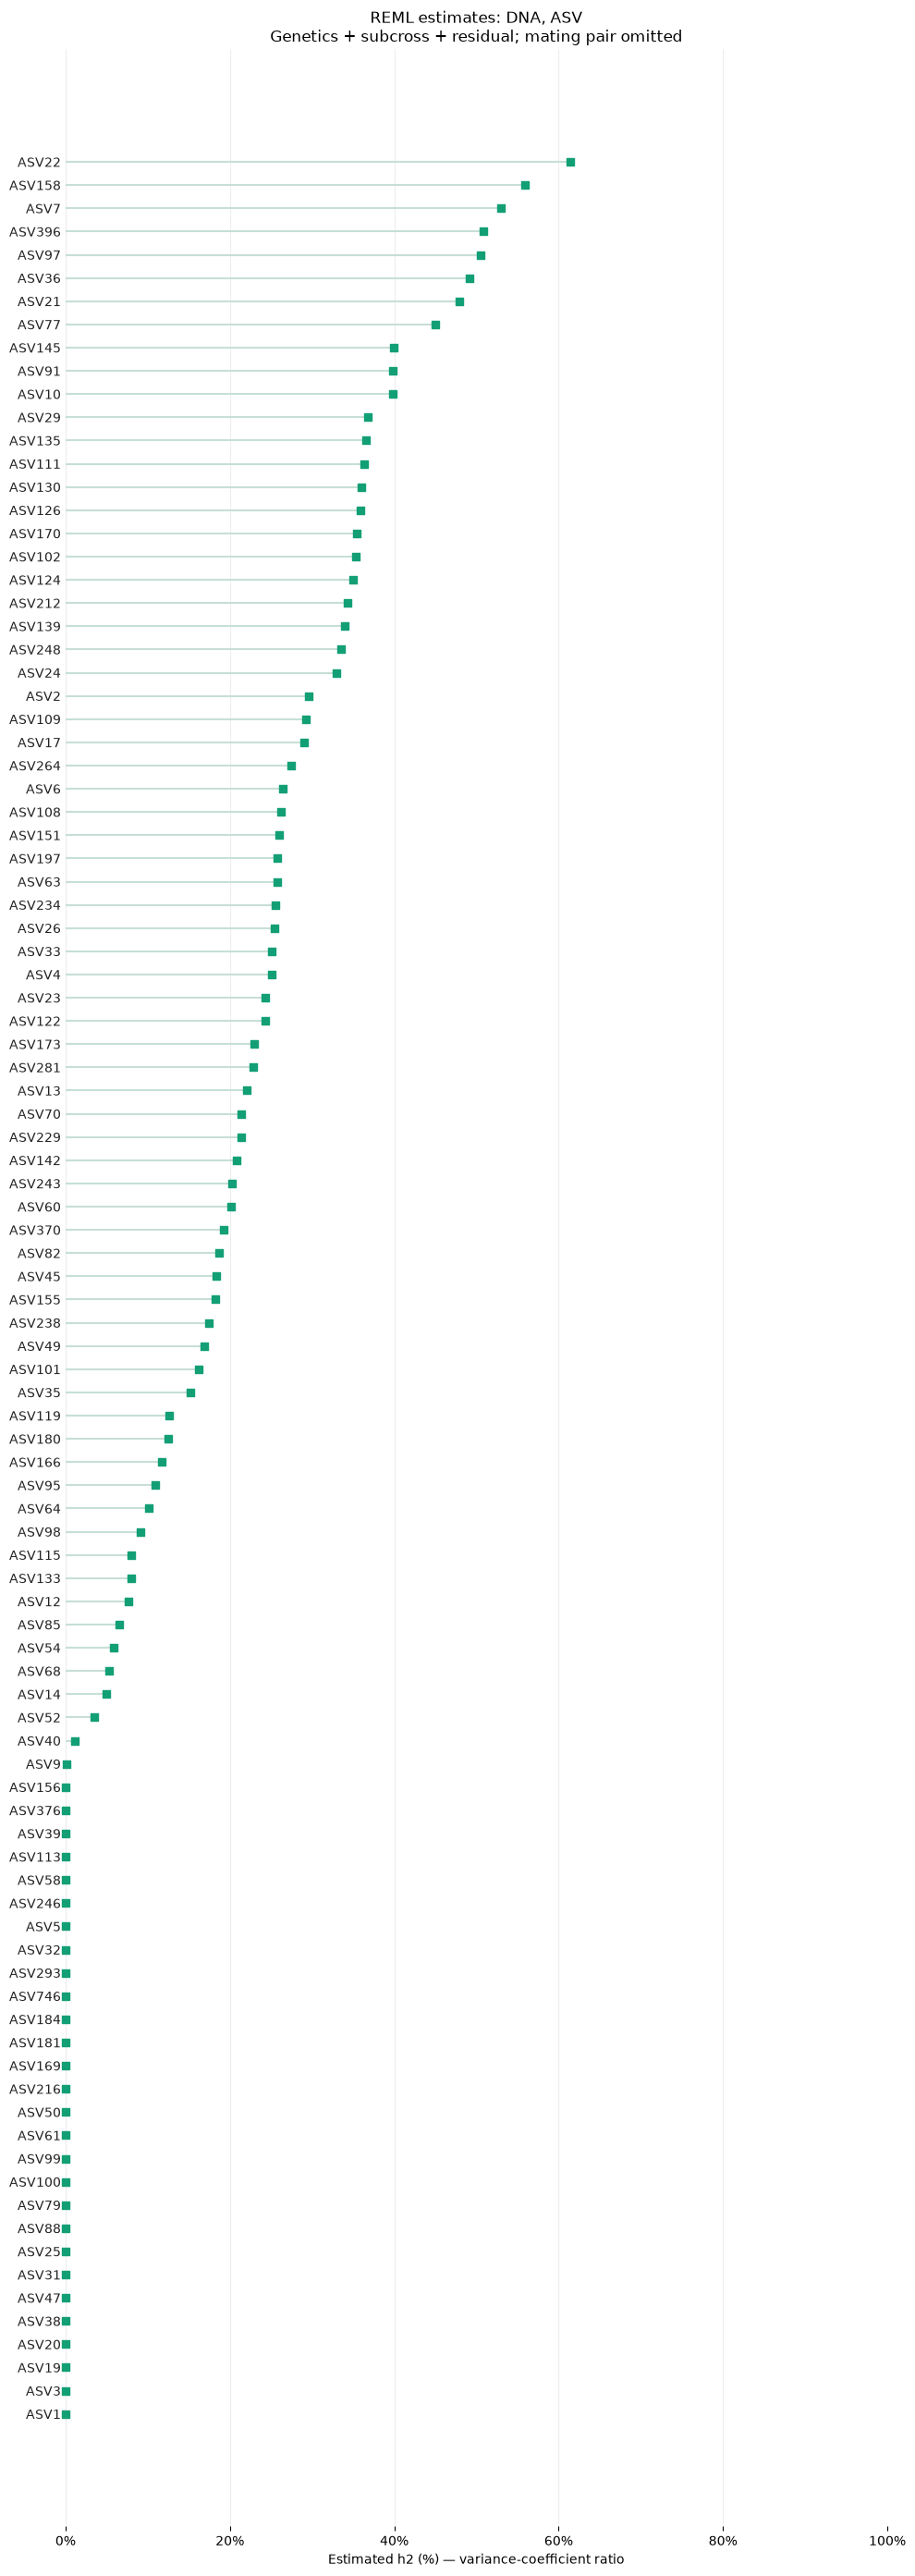

In [140]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Use our estimates directly. Do not read the supplementary workbook here.
plot_data = raw_h2.copy()  # Explicitly select the centered-GRM fit.
if "h2_coefficient" not in plot_data:
    raise ValueError("No heritability estimates: check the REML fits above")
keep = plot_data.status.eq("converged") & np.isfinite(plot_data.h2_coefficient)
if (~keep).any():
    print("Not plotted because the fit needs checking:")
    display(plot_data.loc[~keep, ["status", "h2_coefficient"]])
plot_data = plot_data.loc[keep].sort_values("h2_coefficient")
if plot_data.empty:
    raise ValueError("No converged estimates to plot")

rank_names = {"otu": "ASV", "genus": "Genus", "family": "Family",
              "order": "Order", "class": "Class", "phylum": "Phylum"}
rank_colors = {"otu": "#222222", "genus": "#8a377a", "family": "#35a4a8",
               "order": "#c9444a", "class": "#348447", "phylum": "#bc8b16"}

# Preserve the original taxon keys in results; simplify only the display labels.
def display_taxon(taxon):
    if taxon.startswith("SV"):
        return "ASV" + taxon[2:]
    if len(taxon) > 2 and taxon[1] == "_":
        return taxon[2:]
    return taxon

positions = np.arange(len(plot_data))
percent = 100 * plot_data.h2_coefficient.to_numpy()
fig, ax = plt.subplots(figsize=(10, max(4, 0.27 * len(plot_data) + 1.5)))
ax.hlines(positions, 0, percent, color="#c7dfd5", linewidth=1.5)
ax.scatter(percent, positions, marker="s", color="#139f75", s=35,
           zorder=3, clip_on=False)
ax.set_yticks(positions, [display_taxon(t) for t in plot_data.index])
for tick in ax.get_yticklabels():
    tick.set_color(rank_colors[LEVEL])
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.set_xlabel("Estimated h2 (%) — variance-coefficient ratio")
ax.set_title(f"REML estimates: {ASSAY}, {rank_names[LEVEL]}\n"
             "Genetics + subcross + residual; mating pair omitted")
ax.set_axisbelow(True)
ax.grid(axis="x", color="#ededed")
ax.tick_params(axis="y", length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.tight_layout()

plot_dir = "./heritability_outputs/"
plot_name = f"REML_est_h2_{ASSAY}_{LEVEL}_{TAXA_SELECTION}"
fig.savefig(plot_dir + f"{plot_name}.png", dpi=180, bbox_inches="tight")
plt.show()


In [146]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

# Columns 1/2 = h^2 DNA/RNA; 3/4 = chip; 5/6 = additive; 7/8 = additive + dominance.
# Keep an explicit mapping so we do not confuse the two assays or estimates.
column_pairs = {
    "h2": (1, 2),
    "chip": (3, 4),
    "pve_additive": (5, 6),
    "pve_additive_dominance": (7, 8),
}

# Assign rank using the source label. G_unclassified_* is still a genus-level
# trait, even when its known parent is a family, order, or class.
def taxonomic_level(taxon):
    if taxon.startswith("ASV"):
        return "ASV"
    if taxon.startswith("G_unclassified_"):
        return "Genus"
    for rank in ["Phylum", "Class", "Order", "Family", "Genus"]:
        if taxon.startswith(rank + " "):
            return rank
    raise ValueError(f"Unrecognized taxonomic label: {taxon}")


# Colors approximate the original figure. Taxon colors are independent of
# measure colors: points encode the measure, text encodes taxonomic level.
rank_colors = {
    "Phylum": "#bc8b16", "Class": "#348447", "Order": "#c9444a",
    "Family": "#35a4a8", "Genus": "#8a377a", "ASV": "#222222",
}
measure_styles = {
    "h2": ("s", "#139f75", "Narrow-sense heritability (h^2)"),
    "chip": ("o", "#900d3b", "Chip heritability"),
    "pve_additive": ("^", "#7f9eb5", "PVE additive effect SNPs"),
    "pve_additive_dominance": ("D", "#dfbc13", "PVE additive + dominance effect SNPs"),
}

# This function can later accept independently computed estimates in the same
# format. For now, pass published_results only; don't mix sources silently.
def plot_heritability_panels(table):
    assays = [
        assay for assay in ["DNA", "RNA"]
        if (
            (table.assay == assay)
            & (table.h2 > 0)
            & (table.chip != 0)
        ).any()
    ]
    if not assays:
        raise ValueError("The table contains no taxa with positive h² and nonzero chip estimates")

    panels = [
        table.loc[
            (table.assay == assay)
            & (table.h2 > 0)
            & (table.chip != 0)
        ].sort_values(["h2", "taxon"]).copy()
        for assay in assays
    ]
    height = max(10, max(len(panel) for panel in panels) * 0.23 + 2.4)
    fig, axes = plt.subplots(
        1, len(panels), figsize=(19 if len(panels) == 2 else 10, height),
        squeeze=False
    )
    axes = axes[0]
    fig.subplots_adjust(
        left=0.19, right=0.98, bottom=0.04, top=0.90,
        wspace=0.85 if len(panels) == 2 else 0.25
    )

    for ax, panel, assay in zip(axes, panels, assays):
        positions = np.arange(len(panel))
        ax.set_axisbelow(True)
        ax.grid(axis="x", color="#ececec", linewidth=0.7)
        ax.grid(axis="y", color="#f0f0f0", linewidth=0.6)

        values = panel[list(measure_styles)].to_numpy(float) * 100
        ax.hlines(positions, np.nanmin(values, axis=1), np.nanmax(values, axis=1),
                  color="#c7c7c7", linewidth=0.7, zorder=1)
        for measure, (marker, color, label) in measure_styles.items():
            valid = panel[measure].notna().to_numpy()
            ax.scatter(panel.loc[valid, measure] * 100, positions[valid],
                       marker=marker, color=color, s=24, linewidths=0.5, zorder=3)

        ax.set_yticks(positions, panel.label)
        for tick, rank in zip(ax.get_yticklabels(), panel["rank"]):
            tick.set_color(rank_colors[rank])
            tick.set_fontsize(7)
        ax.tick_params(axis="y", length=0)
        ax.set_xlim(0, 100)
        ax.set_ylim(-1, len(panel))
        ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
        ax.set_xlabel("% variance explained")
        ax.set_title(f"{assay} — {len(panel)} taxa", loc="left", fontsize=13)
        for spine in ax.spines.values():
            spine.set_visible(False)

    measure_handles = [
        Line2D([], [], linestyle="none", marker=marker, color=color,
               label=label, markersize=7)
        for marker, color, label in measure_styles.values()
    ]
    fig.legend(handles=measure_handles, loc="upper center",
               bbox_to_anchor=(0.5, 0.97), ncol=2, frameon=False, fontsize=10)
    rank_handles = [
        Line2D([], [], color=color, linewidth=3, label=rank)
        for rank, color in rank_colors.items()
    ]
    fig.legend(handles=rank_handles, title="Taxonomic level (label colors)",
               loc="upper center", bbox_to_anchor=(0.5, 0.94),
               ncol=6, frameon=False)
    fig.suptitle("Published heritability and SNP PVE (Figure 1A-B replication)",
                 y=0.995, fontsize=15)
    return fig

# Optional plotting helper only. To use it, explicitly load the published
# supplementary table first. Our fitted results are raw_h2 and reml_chip.


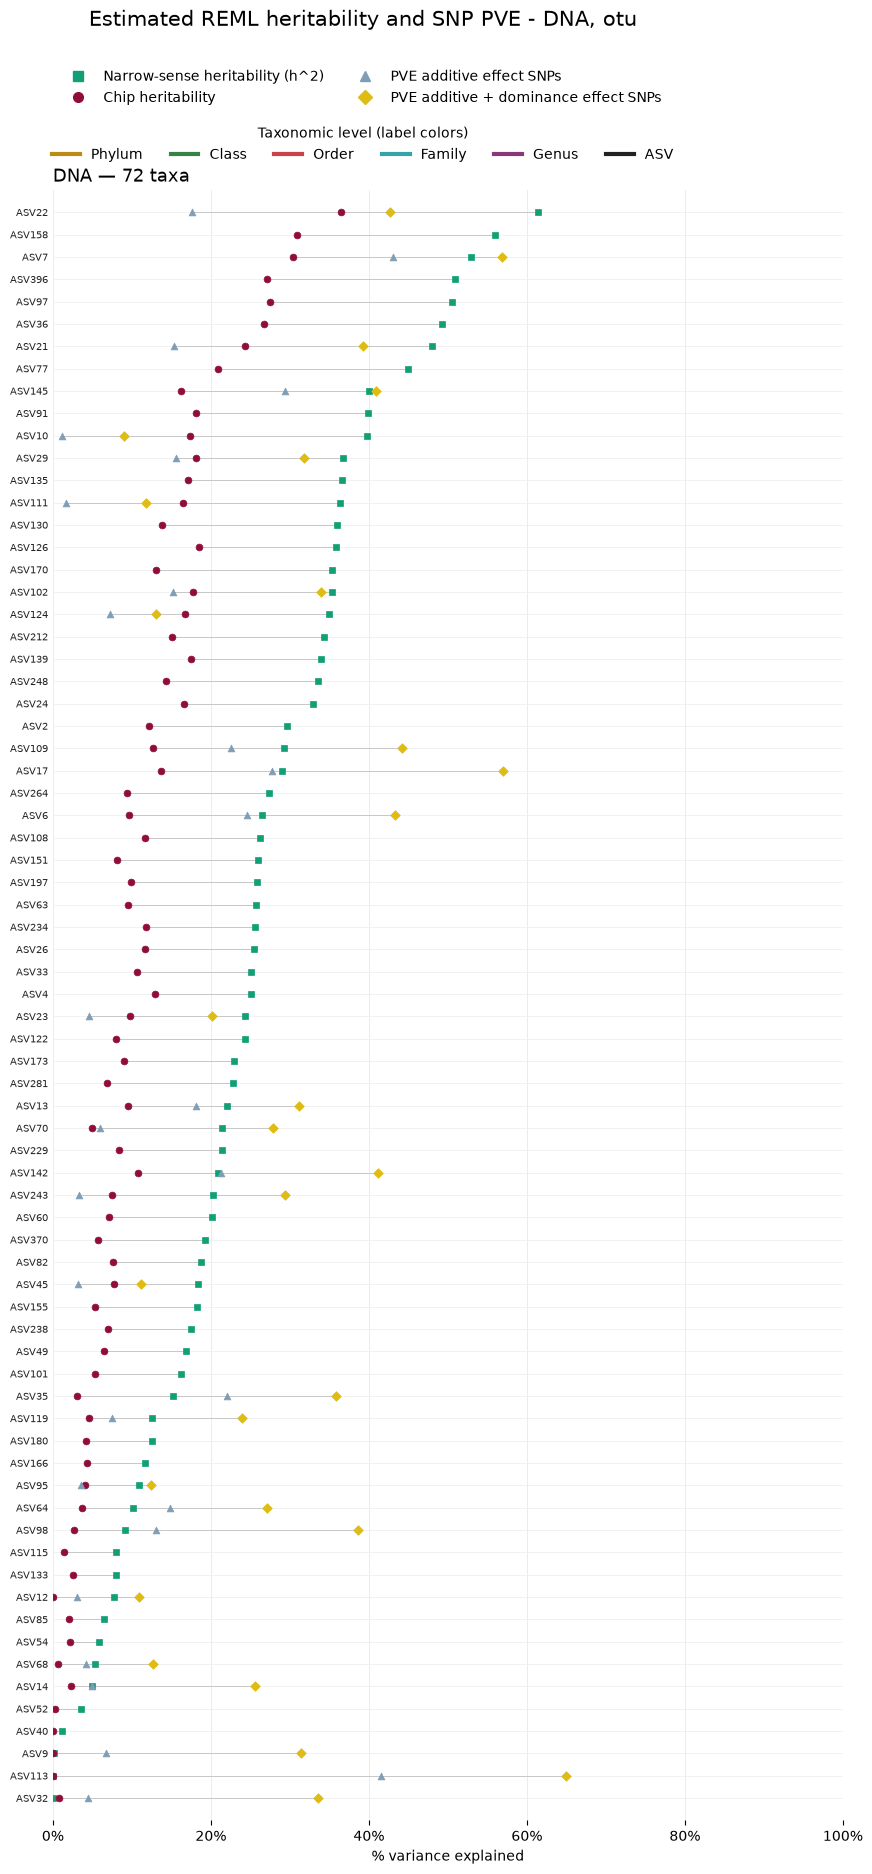

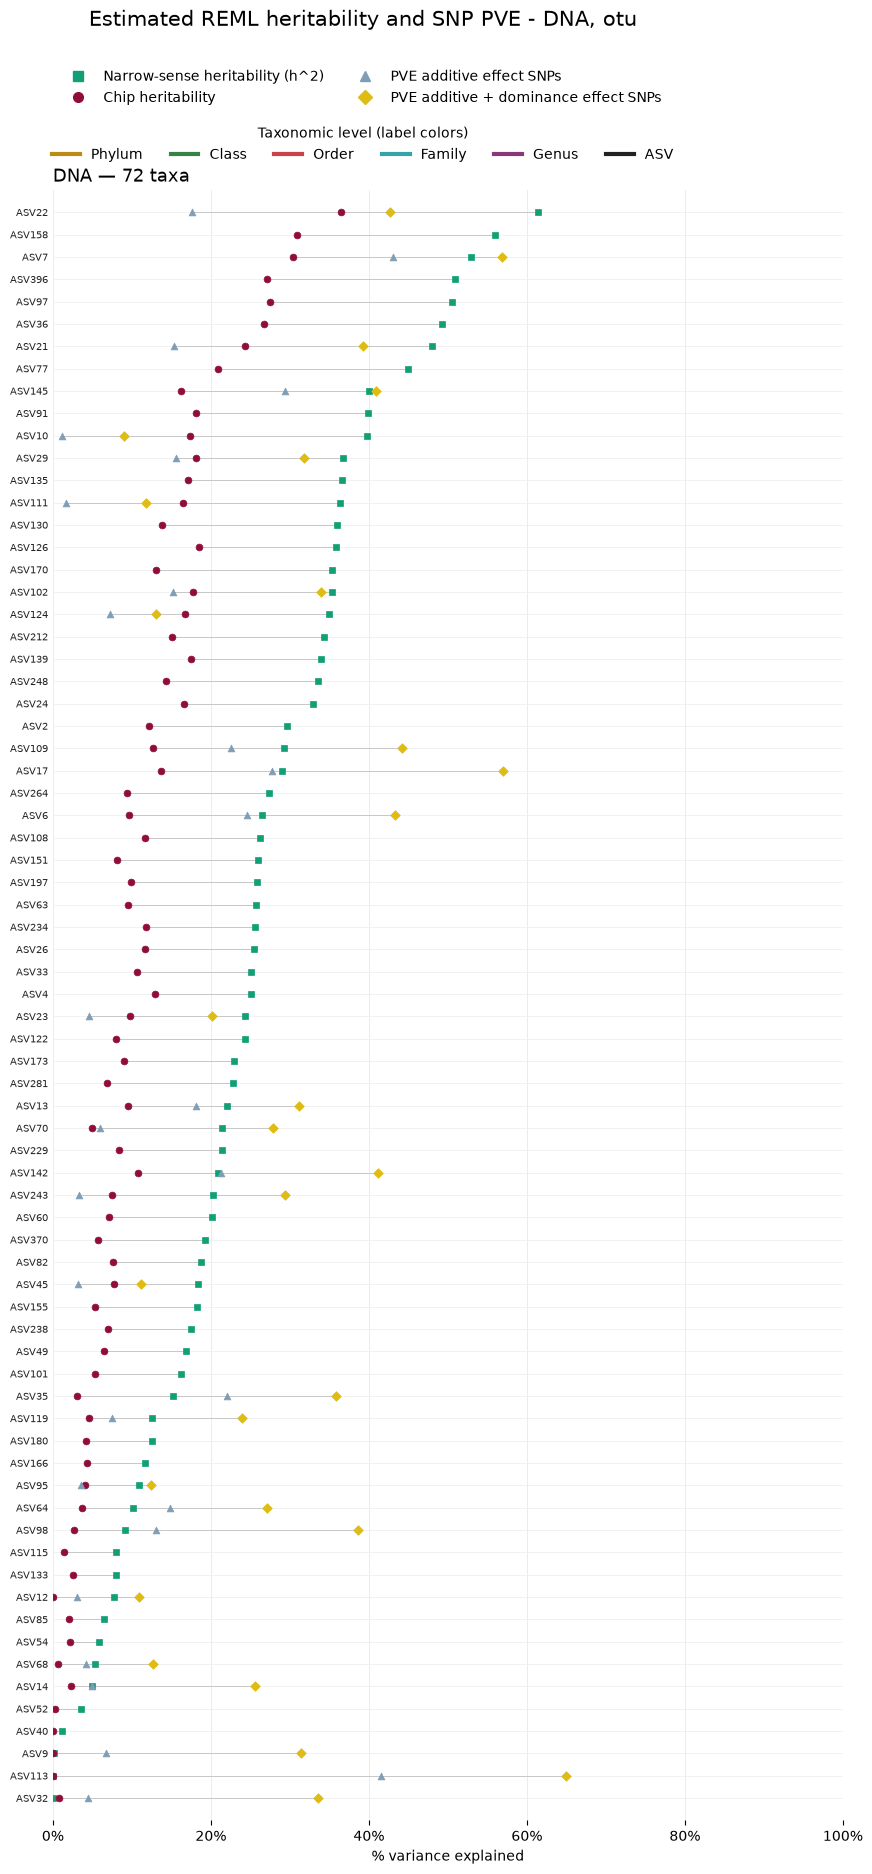

In [147]:
# Rank follows the LEVEL we fitted. otu -> ASV; everything else is its rank.
LEVEL_RANK = {"otu": "ASV", "genus": "Genus", "family": "Family",
              "order": "Order", "class": "Class", "phylum": "Phylum"}


def display_label(taxon, rank):
    # The y-axis label; SVnn is shown as ASVnn to match the figure. Other
    # ranks already carry a readable name.
    if rank == "ASV" and taxon.startswith("SV"):
        return "ASV" + taxon[2:]
    return taxon


def build_plot_table(results, assay, level):
    rank = LEVEL_RANK[level]
    tidy = results.rename(columns={"h2_coefficient": "h2", "chip_h": "chip"}).copy()
    tidy = tidy.reset_index().rename(columns={"index": "taxon"})
    if "taxon" not in tidy.columns:
        tidy = tidy.rename(columns={tidy.columns[0]: "taxon"})
    tidy["assay"] = assay
    tidy["rank"] = rank
    tidy["label"] = [display_label(t, rank) for t in tidy["taxon"]]
    keep = ["assay", "taxon", "label", "rank",
            "h2", "chip", "pve_additive", "pve_additive_dominance"]
    return tidy[keep]


# We have only ASSAY computed in this run; the function draws DNA and RNA
# panels but tolerates an assay being absent (its panel is simply empty).
my_table = build_plot_table(summary_results, ASSAY, LEVEL)
fig = plot_heritability_panels(my_table)
fig.suptitle(f"Estimated REML heritability and SNP PVE - {ASSAY}, {LEVEL}",
             y=0.995, fontsize=15)

out = "./heritability_outputs/"
fig.savefig(out + f"panels_{ASSAY}_{LEVEL}_{TAXA_SELECTION}.png",
            dpi=150, bbox_inches="tight")
fig
